# 02 · Pruning bad channels

A channel with poor contact, a broken electrode or an optode off the scalp adds
noise that every later step would have to work around. Pruning finds such channels
once per subject and removes them from every run:

1. **The pruning window**: channels are judged on the rest recording, so a
   channel's response to the task can never make it look bad. The EEG is judged on
   the whole rest recording, the fNIRS on a stretch of its rest period
2. **EEG**: two passes of [pyprep](https://pyprep.readthedocs.io) criteria; bad
   electrodes are interpolated from their neighbours
3. **fNIRS**: the [cedalion](https://github.com/ibs-lab/cedalion) quality criteria
   on a cleaned amplitude; bad channels are dropped
4. **Every run**: the same channels removed everywhere, so all runs keep one montage

All thresholds are in the pruning config the experiment names (`pruning:`), here
`configs/pruning/default.yaml`.

In [1]:
SUBJECT_CONFIG = "configs/subjects/synthetic/sub01/sub01_snr_fnirs-5_eeg5.yaml"
EXPERIMENT_CONFIG = "configs/experiments/tutorial.yaml"

# For your own data, point SUBJECT_CONFIG at its subject config. If its files are in a
# format the pipeline does not read yet, add a loader for it first (notebook 06).

In [2]:
import dataclasses
import json
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from cedalion.vis.anatomy.scalp_plot import scalp_plot

from src.config import load_experiment, load_subject
from src.loading import load_recordings, load_rest
from src.log import setup_logging
from src.pruning import detect_bad_channels, prune_recordings
from src.pruning.fnirs import clean_amplitude
from src.pruning.prune import MOTOR_EEG_CHANNELS
from src.pruning.segment import rest_window

logger = setup_logging()
warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)


def as_yaml(config) -> str:
    """
    A config section as YAML, the way it is written in its config file.

    Parameters
    ----------
    config : dataclass
        E.g. cfg.pruning.

    Returns
    -------
    str
    """
    return yaml.safe_dump(json.loads(json.dumps(dataclasses.asdict(config), default=str)),
                          sort_keys=False)


subject = load_subject(PROJECT_ROOT / SUBJECT_CONFIG)
cfg = load_experiment(PROJECT_ROOT / EXPERIMENT_CONFIG)
rest = load_rest(subject)

## 1. The pruning window

The fNIRS channels are judged on the first `window_sec` seconds of the rest period
marked in the rest recording's stim table. The EEG channels are judged on the whole
rest recording.

In [3]:
window = rest_window(rest, cfg.pruning.window_sec)
print(f"EEG judged on the whole rest recording: {rest.eeg.times[0]:.1f}-{rest.eeg.times[-1]:.1f} s")
print(f"Rest period {float(rest.stim.onset.iloc[0]):.1f} s for {float(rest.stim.duration.iloc[0]):.1f} s; "
      f"fNIRS judged on {window[0]:.1f}-{window[1]:.1f} s (window_sec: {cfg.pruning.window_sec})")

EEG judged on the whole rest recording: 0.0-175.0 s
Rest period 50.0 s for 75.0 s; fNIRS judged on 50.0-75.0 s (window_sec: 25.0)


## 2. Detecting the bad channels

`detect_bad_channels` runs both detections, the EEG on the whole rest recording and
the fNIRS on the window, and returns a `BadChannels`:
the bad EEG and fNIRS channels, and for each one the criteria that flagged it.

In [4]:
bad = detect_bad_channels(rest, cfg.pruning)

n_eeg = len(rest.eeg.copy().pick("eeg").ch_names)
n_fnirs = rest.fnirs.sizes["channel"]
print(f"EEG:   {len(bad.eeg)} of {n_eeg} bad: {list(bad.eeg)}")
print(f"fNIRS: {len(bad.fnirs)} of {n_fnirs} bad: {list(bad.fnirs)}")

EEG:   4 of 31 bad: ['CP1', 'F8', 'Fp2', 'T8']
fNIRS: 12 of 116 bad: ['S10D35', 'S12D19', 'S12D22', 'S12D36', 'S13D37', 'S15D3', 'S15D38', 'S16D18', 'S16D39', 'S3D32', 'S5D33', 'S6D34']


### EEG: which criterion flagged each channel

Pass 1 judges each channel on its own: NaN values, a flat signal, an unusual
amplitude (`deviation`) or high-frequency noise. Then the EEG is re-referenced to the
average of the channels pass 1 kept, and pass 2 compares the channels with each
other: low correlation with the rest, dropouts, low SNR and RANSAC (how well the
other channels predict this one). A channel flagged in either pass is bad.

In [5]:
def eeg_table(bad_channels) -> pd.DataFrame:
    """
    One row per bad EEG channel, one column per pass and criterion.

    Parameters
    ----------
    bad_channels : BadChannels

    Returns
    -------
    pd.DataFrame
        True where the criterion flagged the channel.
    """
    detail = {f"{pass_name}: {criterion.removeprefix('bad_by_')}": flagged
              for pass_name, criteria in bad_channels.eeg_detail.items()
              for criterion, flagged in criteria.items()}
    rows = {ch: {name: ch in flagged for name, flagged in detail.items()}
            for ch in bad_channels.eeg}
    return pd.DataFrame.from_dict(rows, orient="index", columns=list(detail))


eeg_table(bad)

,pass1: nan,pass1: flat,pass1: deviation,pass1: hf_noise,pass2: correlation,pass2: dropout,pass2: SNR,pass2: ransac
CP1,False,False,False,True,True,False,False,False
F8,False,False,True,False,True,False,False,False
Fp2,False,False,False,False,True,False,False,False
T8,False,False,False,False,True,False,False,False


### fNIRS: which check each channel failed

The fNIRS checks run on a cleaned amplitude: converted to optical density, motion
corrected (TDDR, then wavelet) and high-pass filtered, so that slow drift and motion
spikes are not mistaken for bad coupling. A channel must pass every check:

| Check | What it tests |
|---|---|
| `sd_dist` | the source-detector distance is within `sd_range_mm` |
| `mean_amp` | the mean amplitude is within `amp_range_v` |
| `snr` | the mean over the standard deviation is above `snr_threshold` |
| `sci_psp` | the heartbeat is visible at both wavelengths (scalp coupling index and peak spectral power) in enough time windows |

In [6]:
def fnirs_table(bad_channels) -> pd.DataFrame:
    """
    One row per bad fNIRS channel, one column per check.

    Parameters
    ----------
    bad_channels : BadChannels

    Returns
    -------
    pd.DataFrame
        True where the channel failed the check.
    """
    detail = bad_channels.fnirs_detail
    rows = {ch: {check: ch in failing for check, failing in detail.items()}
            for ch in bad_channels.fnirs}
    return pd.DataFrame.from_dict(rows, orient="index", columns=list(detail))


fnirs_table(bad)

,sd_dist,mean_amp,snr,sci_psp
S10D35,True,False,False,True
S12D19,False,False,False,True
S12D22,False,False,False,True
S12D36,True,True,False,True
S13D37,True,False,False,False
S15D3,False,False,False,True
S15D38,True,False,False,False
S16D18,False,False,False,True
S16D39,True,False,False,False
S3D32,True,True,False,True


### Where the bad channels are

Bad electrodes in red (left). Right: each fNIRS channel coloured by how many checks
it failed; every channel above 0 is dropped.

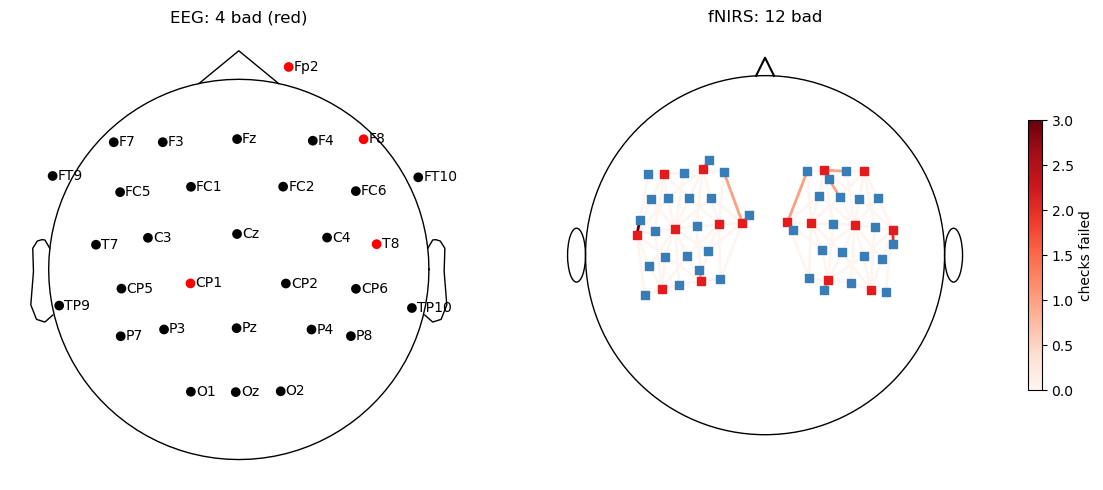

In [7]:
fails = pd.Series(0, index=[str(c) for c in rest.fnirs.channel.values])
for failing in bad.fnirs_detail.values():
    fails[list(failing)] += 1

fig, (ax_eeg, ax_fnirs) = plt.subplots(1, 2, figsize=(12, 5))
eeg = rest.eeg.copy().pick("eeg")
eeg.info["bads"] = list(bad.eeg)
eeg.plot_sensors(kind="topomap", show_names=True, axes=ax_eeg, show=False)
ax_eeg.set_title(f"EEG: {len(bad.eeg)} bad (red)")
scalp_plot(rest.fnirs, rest.geo3d, fails.values, ax=ax_fnirs, cmap="Reds", vmin=0,
           vmax=max(1, fails.max()), title=f"fNIRS: {len(bad.fnirs)} bad",
           cb_label="checks failed")
plt.tight_layout()
plt.show()

### A kept and a dropped fNIRS channel

The cleaned amplitude the checks see, for the kept channel with the most and the
dropped channel with the fewest failed checks. A well coupled channel shows the
heartbeat (about 1 Hz) at both wavelengths.

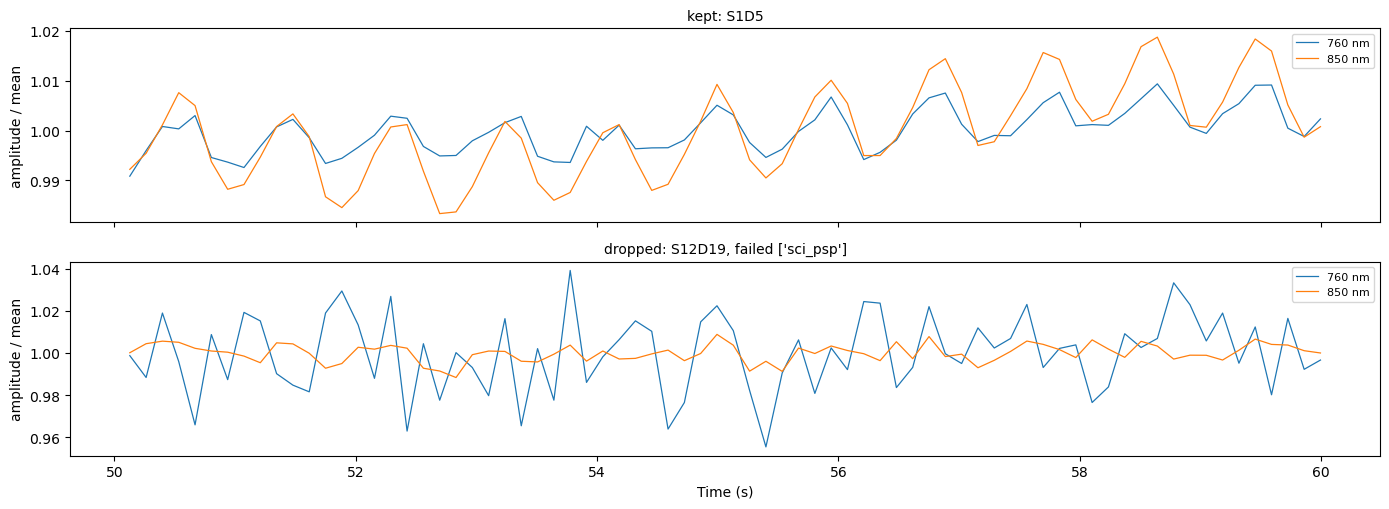

In [8]:
cleaned = clean_amplitude(rest.fnirs, window, cfg.pruning.fnirs)
kept = [c for c in fails.index if fails[c] == 0]
examples = {"kept": kept[0]}
if len(bad.fnirs):
    examples["dropped"] = min(bad.fnirs, key=lambda c: fails[c])

fig, axes = plt.subplots(len(examples), 1, figsize=(14, 2.6 * len(examples)), sharex=True,
                         squeeze=False)
for ax, (label, ch) in zip(axes[:, 0], examples.items()):
    seg = cleaned.sel(channel=ch, time=slice(window[0], window[0] + 10)).pint.dequantify()
    for wl in seg.wavelength.values:
        values = seg.sel(wavelength=wl).values
        ax.plot(seg.time, values / values.mean(), lw=0.9, label=f"{wl:g} nm")
    failed = [check for check, failing in bad.fnirs_detail.items() if ch in failing]
    ax.set_title(f"{label}: {ch}" + (f", failed {failed}" if failed else ""), fontsize=10)
    ax.set_ylabel("amplitude / mean")
    ax.legend(loc="upper right", fontsize=8)
axes[-1, 0].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()

## 3. Removing them from every run

`prune_recordings` detects the bad channels as above and removes them from every run:
bad electrodes are interpolated from their neighbours, so every run keeps the full
EEG montage, and bad fNIRS channels are dropped. It stops the run if an electrode
over the motor cortex is bad, since interpolating it would replace exactly the signal
the analysis needs:

In [9]:
print(f"Motor electrodes that must not be bad: {MOTOR_EEG_CHANNELS}")

Motor electrodes that must not be bad: ('C3', 'C4')


In [10]:
recordings = load_recordings(subject)
pruned, bad_channels = prune_recordings(recordings, rest, cfg.pruning)

before, after = recordings[0], pruned[0]
print(f"{len(pruned)} runs pruned with the same lists")
print(f"EEG:   {len(before.eeg.copy().pick('eeg').ch_names)} channels before, "
      f"{len(after.eeg.copy().pick('eeg').ch_names)} after ({len(bad_channels.eeg)} interpolated)")
print(f"fNIRS: {before.fnirs.sizes['channel']} channels before, {after.fnirs.sizes['channel']} after")

15 runs pruned with the same lists
EEG:   31 channels before, 31 after (4 interpolated)
fNIRS: 116 channels before, 104 after


## Changing the thresholds

Every threshold above comes from the pruning config. To change one, copy
`configs/pruning/default.yaml`, edit it, and point the experiment's `pruning:` at the
copy. The values used here:

In [11]:
print(as_yaml(cfg.pruning))

random_state: 42
window_sec: 25.0
eeg:
  line_freqs:
  - 50.0
  - 100.0
  ransac: true
  pass1:
    flat_threshold: 1.0e-15
    deviation_threshold: 5.0
    hf_noise_threshold: 5.0
  pass2:
    correlation_secs: 1.0
    correlation_threshold: 0.4
    correlation_frac_bad: 0.1
    ransac_n_samples: 50
    ransac_sample_prop: 0.25
    ransac_corr_thresh: 0.75
    ransac_frac_bad: 0.4
    ransac_window_secs: 5.0
fnirs:
  highpass_hz: 0.01
  butter_order: 4
  sd_range_mm:
  - 10.0
  - 45.0
  amp_range_v:
  - 0.001
  - 0.85
  snr_threshold: 3.0
  sci_threshold: 0.5
  psp_threshold: 0.05
  window_length_s: 5.0
  time_pass_fraction: 0.5



## Next

Notebook 03 turns the pruned runs into the signals the models are fit on.